Sel 0 — Instalasi

In [1]:
!pip install polars duckdb plotly pyarrow pandas nbformat

Sel 1 — Import dan muat data

In [2]:
import os
import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

pio.templates.default = "plotly_white"
pl.Config.set_tbl_rows(20); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(60)

path_data = "/home/jovyan/work/data/processed/iged_bersih.parquet"

print("Folder kerja notebook :", os.getcwd())
print("File ada?             :", os.path.exists(path_data))

df = pl.read_parquet(path_data)
print(f"Data loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom  <- {path_data}")
df.schema

Folder kerja notebook : /home/jovyan/work/notebooks
File ada?             : True
Data loaded: 1,308,276 baris x 7 kolom  <- /home/jovyan/work/data/processed/iged_bersih.parquet


Schema([('src', String),
        ('trg', String),
        ('category', String),
        ('split', String),
        ('src_len', UInt32),
        ('trg_len', UInt32),
        ('trg_kata', UInt32)])

Sel 2 — Preview

In [3]:
df.head(5)

src,trg,category,split,src_len,trg_len,trg_kata
str,str,str,str,u32,u32,u32
"""Ketika menunjuk titik dan diatas tanah milik negear dan tida…","""Ketika menunjuk titik dan diatas tanah milik negera dan tida…","""sintaksis_frasa""","""train""",129,129,19
"""Untuk itu, pihak Daker Madinah harus bergerak cepat menginpu…","""Untuk itu, pihak Daker Madinah harus bergerak cepat menginpu…","""diksi""","""train""",325,324,47
"""Laporan Wartawan Tribunnews.com, Wahyu Aji TRIBUNNEWS.COM, J…","""Laporan Wartawan Tribunnews.com, Wahyu Aji TRIBUNNEWS.COM, J…","""preposisi""","""train""",341,353,45
"""Zambia merupakan salah satu negara lewat benua Afrika memili…","""Zambia merupakan salah satu negara di benua Afrika yang memi…","""ambigu""","""train""",100,102,15
"""Busquets yang-yang memang-memang selalu menjadi pilihan utam…","""Busquets yang memang selalu menjadi pilihan utama sejak era …","""reduplikasi""","""train""",162,150,22


Sel 3 — Feature engineering

In [4]:
df = (
    df.with_row_index("row_id")
      .with_columns(
          pl.col("row_id").cast(pl.Int64),
          pl.col("src_len").cast(pl.Int32),
          pl.col("trg_len").cast(pl.Int32),
          pl.col("trg_kata").cast(pl.Int32),
      )
      .with_columns(
          (pl.col("trg_len") - pl.col("src_len")).alias("selisih_len"),
          (pl.col("trg_len") / pl.col("trg_kata")).alias("char_per_kata"),
          pl.col("category").str.ends_with("_claude").alias("is_claude"),
          pl.when(pl.col("category").str.ends_with("_claude"))
            .then(pl.lit("sintetis (Claude)")).otherwise(pl.lit("asli")).alias("sumber"),
      )
      .with_columns(pl.col("selisih_len").abs().alias("abs_selisih"))
)
df.select("row_id","category","split","src_len","trg_len","selisih_len","char_per_kata","sumber").head(5)

row_id,category,split,src_len,trg_len,selisih_len,char_per_kata,sumber
i64,str,str,i32,i32,i32,f64,str
0,"""sintaksis_frasa""","""train""",129,129,0,6.789474,"""asli"""
1,"""diksi""","""train""",325,324,-1,6.893617,"""asli"""
2,"""preposisi""","""train""",341,353,12,7.844444,"""asli"""
3,"""ambigu""","""train""",100,102,2,6.8,"""asli"""
4,"""reduplikasi""","""train""",162,150,-12,6.818182,"""asli"""


Sel 4 — Kualitas data

In [5]:
n = df.height
kualitas = {
    "Total baris": n,
    "Nilai null (semua kolom)": int(df.null_count().sum_horizontal().item()),
    "Duplikat pasangan (src,trg)": n - df.select("src","trg").n_unique(),
    "Duplikat `src` (src sama, trg beda)": n - df["src"].n_unique(),
    "Pasangan src == trg (tanpa koreksi)": df.filter(pl.col("src") == pl.col("trg")).height,
    "src_len < 30 karakter": df.filter(pl.col("src_len") < 30).height,
    "src_len > 400 karakter": df.filter(pl.col("src_len") > 400).height,
    "src_len maksimum": df["src_len"].max(),
    "Baris sintetis (_claude)": df["is_claude"].sum(),
}
for k, v in kualitas.items():
    print(f"{k:<40}: {v:>10,}")

Total baris                             :  1,308,276
Nilai null (semua kolom)                :          0
Duplikat pasangan (src,trg)             :          0
Duplikat `src` (src sama, trg beda)     :         61
Pasangan src == trg (tanpa koreksi)     :          0
src_len < 30 karakter                   :     12,495
src_len > 400 karakter                  :     17,327
src_len maksimum                        :        495
Baris sintetis (_claude)                :     10,411


Sel 5 — Statistik per kategori

In [6]:
ringkas = (
    df.group_by("category")
      .agg(
          pl.len().alias("n"),
          (pl.len() / df.height * 100).round(2).alias("persen"),
          pl.col("src_len").mean().round(1).alias("src_len_mean"),
          pl.col("trg_len").mean().round(1).alias("trg_len_mean"),
          pl.col("selisih_len").mean().round(2).alias("selisih_mean"),
          pl.col("selisih_len").median().alias("selisih_median"),
          pl.col("selisih_len").std().round(2).alias("selisih_std"),
          (pl.col("selisih_len") == 0).mean().round(3).alias("p_panjang_sama"),
      )
      .sort("selisih_mean")
)
ringkas

category,n,persen,src_len_mean,trg_len_mean,selisih_mean,selisih_median,selisih_std,p_panjang_sama
str,u32,f64,f64,f64,f64,f64,f64,f64
"""diksi_claude""",3464,0.26,181.0,139.8,-41.21,-38.0,20.03,0.0
"""pembentukan_kata""",160389,12.26,157.1,138.1,-19.07,-20.0,8.54,0.002
"""pleonasme""",26664,2.04,152.1,136.7,-15.41,-15.0,4.96,0.0
"""reduplikasi""",86765,6.63,161.8,150.2,-11.54,-11.0,5.01,0.002
"""ambigu_claude""",3469,0.27,146.8,136.7,-10.11,-12.0,17.96,0.016
"""preposisi""",162031,12.39,156.3,153.7,-2.56,-3.0,7.42,0.044
"""ambigu""",61777,4.72,164.2,163.1,-1.1,-1.0,4.73,0.079
"""sintaksis_frasa""",248241,18.97,137.5,137.5,0.0,0.0,0.0,1.0
"""diksi""",138567,10.59,138.1,138.6,0.55,0.0,3.12,0.153


Sel 6 — Statistik global dan per split

In [7]:
from IPython.display import display

# Statistik global dalam format vertikal (lebih mudah dibaca)
global_stat = df.select(
    pl.col("src_len").mean().alias("src_len: rata-rata"),
    pl.col("src_len").std().alias("src_len: std"),
    pl.col("src_len").median().alias("src_len: median"),
    pl.col("src_len").quantile(0.95).alias("src_len: p95"),
    pl.col("src_len").quantile(0.99).alias("src_len: p99"),
    pl.col("trg_len").mean().alias("trg_len: rata-rata"),
    pl.col("trg_kata").mean().alias("trg_kata: rata-rata"),
    pl.col("selisih_len").quantile(0.01).alias("selisih_len: p1"),
    pl.col("selisih_len").quantile(0.99).alias("selisih_len: p99"),
).transpose(include_header=True, header_name="metrik", column_names=["nilai"])

print("Statistik global")
display(global_stat.with_columns(pl.col("nilai").round(2)))

# Ringkasan per split
per_split = (
    df.group_by("split")
      .agg(pl.len().alias("n"),
           pl.col("src_len").mean().round(2).alias("src_len_mean"),
           pl.col("selisih_len").mean().round(3).alias("selisih_mean"),
           pl.col("row_id").min().alias("row_min"),
           pl.col("row_id").max().alias("row_max"))
      .sort("row_min")
)
print("Ringkasan per split")
display(per_split)

Statistik global


metrik,nilai
str,f64
"""src_len: rata-rata""",144.8
"""src_len: std""",80.54
"""src_len: median""",127.0
"""src_len: p95""",304.0
"""src_len: p99""",415.0
"""trg_len: rata-rata""",142.59
"""trg_kata: rata-rata""",19.61
"""selisih_len: p1""",-32.0
"""selisih_len: p99""",16.0


Ringkasan per split


split,n,src_len_mean,selisih_mean,row_min,row_max
str,u32,f64,f64,i64,i64
"""train""",1046620,144.77,-2.208,0,1046619
"""valid""",130875,144.92,-2.225,1046620,1177494
"""test""",130781,144.93,-2.215,1177495,1308275


Sel 7 — Temporal: group_by_dynamic, rolling_mean, shift (sumbu waktu = row_id)

In [8]:
WINDOW = 5000

win = (
    df.sort("row_id")
      .group_by_dynamic("row_id", every=f"{WINDOW}i", closed="left")
      .agg(
          pl.len().alias("n"),
          pl.col("src_len").mean().alias("src_len_mean"),
          pl.col("selisih_len").mean().alias("selisih_mean"),
          (pl.col("category") == "afiksasi").mean().alias("p_afiksasi"),
          pl.col("is_claude").mean().alias("p_claude"),
      )
      .filter(pl.col("n") == WINDOW)
      .with_columns(
          pl.col("src_len_mean").rolling_mean(window_size=10).alias("src_len_ma10"),
          pl.col("selisih_mean").rolling_mean(window_size=10).alias("selisih_ma10"),
          pl.col("src_len_mean").shift(1).alias("src_len_prev"),
      )
      .with_columns((pl.col("src_len_mean") - pl.col("src_len_prev")).alias("delta_src_len"))
)
print(f"{win.height} jendela x {WINDOW:,} baris")
win.head(8)

261 jendela x 5,000 baris


row_id,n,src_len_mean,selisih_mean,p_afiksasi,p_claude,src_len_ma10,selisih_ma10,src_len_prev,delta_src_len
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64
0,5000,144.6252,-2.1544,0.1972,0.0062,null,null,null,null
5000,5000,144.201,-2.3782,0.182,0.0082,null,null,144.6252,-0.4242
10000,5000,144.124,-2.3192,0.197,0.0076,null,null,144.201,-0.077
15000,5000,144.949,-2.2046,0.2008,0.0074,null,null,144.124,0.825
20000,5000,144.1402,-2.2552,0.1994,0.0094,null,null,144.949,-0.8088
25000,5000,145.5438,-2.4222,0.2132,0.0094,null,null,144.1402,1.4036
30000,5000,143.7328,-1.9262,0.2046,0.0074,null,null,145.5438,-1.811
35000,5000,145.3008,-2.168,0.2054,0.0092,null,null,143.7328,1.568


Sel 8 — Uji tren dan autokorelasi

In [9]:
ac1 = win.select(pl.corr("src_len_mean", "src_len_prev")).item()
tren = win.select(pl.corr("row_id", "src_len_mean")).item()
print(f"Autokorelasi lag-1 antar-jendela        : {ac1:+.3f}")
print(f"Korelasi row_id vs rata-rata panjang    : {tren:+.3f}")
print(f"Rentang rata-rata panjang per jendela   : {win['src_len_mean'].min():.1f} - {win['src_len_mean'].max():.1f}")
print(f"Rentang rata-rata selisih panjang       : {win['selisih_mean'].min():.2f} - {win['selisih_mean'].max():.2f}")

Autokorelasi lag-1 antar-jendela        : -0.009
Korelasi row_id vs rata-rata panjang    : +0.100
Rentang rata-rata panjang per jendela   : 141.6 - 147.9
Rentang rata-rata selisih panjang       : -2.59 - -1.81


Sel 9 — DuckDB: moving average per kategori

In [10]:
q_ma = '''
WITH w AS (
    SELECT row_id, category,
           AVG(selisih_len) OVER (PARTITION BY category ORDER BY row_id
                                  ROWS BETWEEN 999 PRECEDING AND CURRENT ROW) AS ma_1000
    FROM df
)
SELECT category, row_id // 50000 * 50000 AS blok, ROUND(AVG(ma_1000), 2) AS ma_1000
FROM w GROUP BY 1, 2 ORDER BY 1, 2
'''
ma_kat = duckdb.sql(q_ma).pl()
ma_kat.group_by("category").agg(
    pl.col("ma_1000").mean().round(2).alias("rata2_MA"),
    pl.col("ma_1000").min().alias("min_MA"),
    pl.col("ma_1000").max().alias("max_MA"),
    (pl.col("ma_1000").max() - pl.col("ma_1000").min()).round(2).alias("rentang"),
).sort("rata2_MA")

category,rata2_MA,min_MA,max_MA,rentang
str,f64,f64,f64,f64
"""diksi_claude""",-40.99,-41.72,-38.19,3.53
"""pembentukan_kata""",-19.07,-19.32,-18.88,0.44
"""pleonasme""",-15.41,-15.6,-15.16,0.44
"""reduplikasi""",-11.54,-11.7,-11.34,0.36
"""ambigu_claude""",-10.32,-11.89,-9.43,2.46
"""preposisi""",-2.56,-2.7,-2.44,0.26
"""ambigu""",-1.1,-1.35,-0.91,0.44
"""sintaksis_frasa""",0.0,0.0,0.0,0.0
"""diksi""",0.55,0.47,0.62,0.15


Sel 10 — DuckDB: PERCENT_RANK

In [11]:
q_rank = '''
SELECT category, COUNT(*) AS n,
       MIN(src_len) FILTER (WHERE pr >= 0.50) AS p50,
       MIN(src_len) FILTER (WHERE pr >= 0.90) AS p90,
       MIN(src_len) FILTER (WHERE pr >= 0.99) AS p99
FROM (SELECT category, src_len,
             PERCENT_RANK() OVER (PARTITION BY category ORDER BY src_len) AS pr FROM df)
GROUP BY category ORDER BY p50
'''
duckdb.sql(q_rank).pl()

category,n,p50,p90,p99
str,i64,i32,i32,i32
"""kelengkapan_kalimat""",155833,114,240,412
"""diksi""",138567,121,242,407
"""afiksasi""",257598,121,238,398
"""sintaksis_frasa""",248241,121,242,409
"""pleonasme_claude""",3478,126,232,362
"""pleonasme""",26664,135,256,424
"""ambigu_claude""",3469,136,233,375
"""preposisi""",162031,140,265,428
"""pembentukan_kata""",160389,142,269,431


Sel 11 — DuckDB: ECDF (SUM OVER)

In [12]:
q_ecdf = '''
WITH b AS (
    SELECT category, (src_len // 25) * 25 AS bin_len, COUNT(*) AS n FROM df GROUP BY 1, 2
)
SELECT category, bin_len,
       SUM(n) OVER (PARTITION BY category ORDER BY bin_len) / SUM(n) OVER (PARTITION BY category) AS cdf
FROM b ORDER BY category, bin_len
'''
ecdf = duckdb.sql(q_ecdf).pl()
ecdf.head()

category,bin_len,cdf
str,i32,f64
"""afiksasi""",0,0.003669
"""afiksasi""",25,0.057667
"""afiksasi""",50,0.194101
"""afiksasi""",75,0.367188
"""afiksasi""",100,0.52507


Sel 12 — DuckDB: LAG (drift komposisi kategori)

In [13]:
q_lag = '''
WITH k AS (
    SELECT row_id // 200000 AS blok, category,
           COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (PARTITION BY row_id // 200000) AS porsi
    FROM df GROUP BY 1, 2
)
SELECT category, blok, ROUND(porsi*100, 2) AS porsi_pct,
       ROUND((porsi - LAG(porsi) OVER (PARTITION BY category ORDER BY blok))*100, 3) AS delta_pp
FROM k WHERE blok < 6
ORDER BY ABS(delta_pp) DESC NULLS LAST LIMIT 5
'''
duckdb.sql(q_lag).pl()

category,blok,porsi_pct,delta_pp
str,i64,f64,f64
"""preposisi""",5,12.32,-0.177
"""kelengkapan_kalimat""",5,11.85,-0.165
"""sintaksis_frasa""",3,18.89,-0.16
"""diksi""",5,10.65,0.138
"""kelengkapan_kalimat""",4,12.02,0.138


Sel 13 — Visualisasi 1: tren dengan range slider

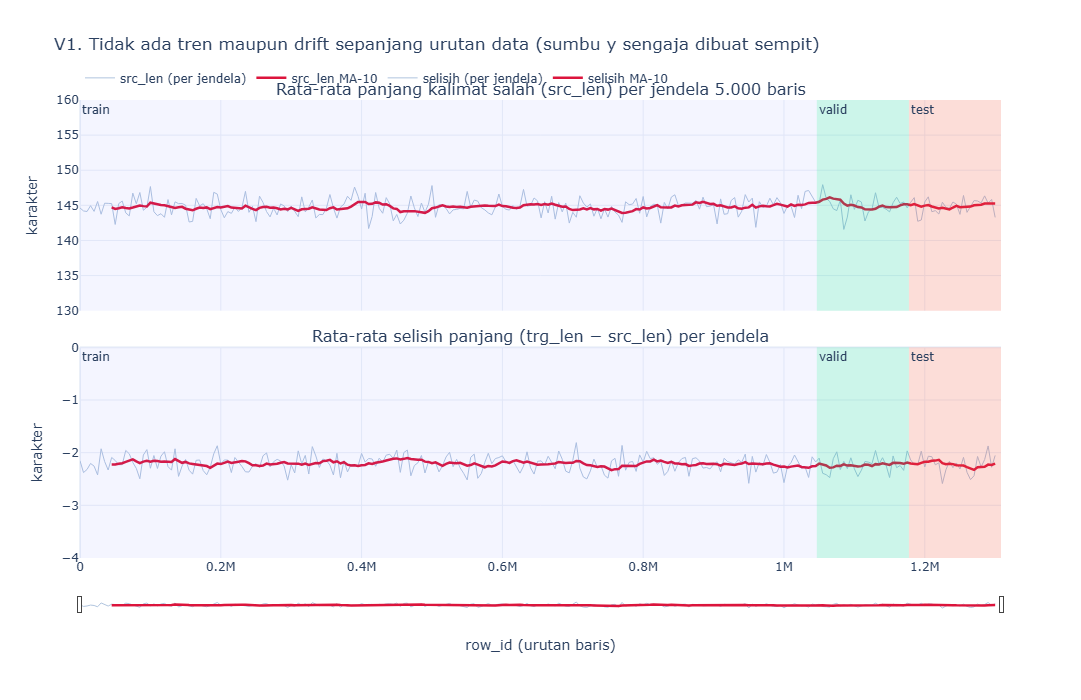

In [14]:
bounds = (df.group_by("split").agg(pl.col("row_id").min().alias("x0"), (pl.col("row_id").max()+1).alias("x1"))
            .sort("x0").to_dicts())
warna_split = {"train": "rgba(99,110,250,0.07)", "valid": "rgba(0,204,150,0.20)", "test": "rgba(239,85,59,0.20)"}

fig1 = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                     subplot_titles=("Rata-rata panjang kalimat salah (src_len) per jendela 5.000 baris",
                                     "Rata-rata selisih panjang (trg_len − src_len) per jendela"))
for r, (kol, ma, nama) in enumerate([("src_len_mean","src_len_ma10","src_len"),
                                      ("selisih_mean","selisih_ma10","selisih")], start=1):
    fig1.add_trace(go.Scatter(x=win["row_id"], y=win[kol], mode="lines", name=f"{nama} (per jendela)",
                              line=dict(color="lightsteelblue", width=1)), row=r, col=1)
    fig1.add_trace(go.Scatter(x=win["row_id"], y=win[ma], mode="lines", name=f"{nama} MA-10",
                              line=dict(color="crimson", width=2.5)), row=r, col=1)
for b in bounds:
    fig1.add_vrect(x0=b["x0"], x1=b["x1"], fillcolor=warna_split[b["split"]], line_width=0,
                   annotation_text=b["split"], annotation_position="top left", row="all", col=1)
fig1.update_yaxes(range=[130, 160], row=1, col=1, title="karakter")
fig1.update_yaxes(range=[-4, 0], row=2, col=1, title="karakter")
fig1.update_xaxes(title_text="row_id (urutan baris)", rangeslider=dict(visible=True, thickness=0.06), row=2, col=1)
fig1.update_layout(height=700, hovermode="x unified", legend=dict(orientation="h", y=1.08),
                   title="V1. Tidak ada tren maupun drift sepanjang urutan data (sumbu y sengaja dibuat sempit)")
fig1.show()

Sel 14 — Visualisasi 2: box plot distribusi dan outlier

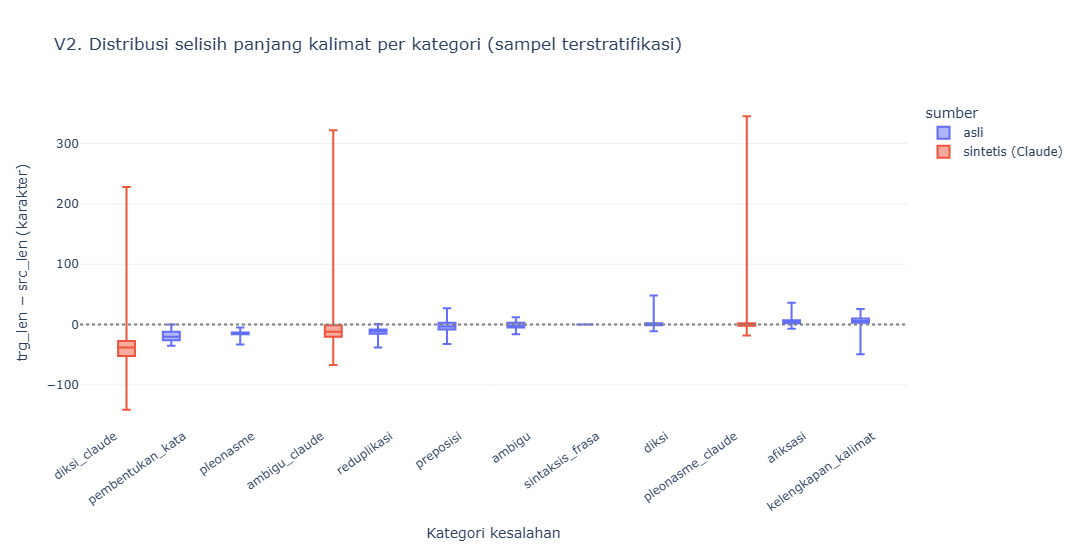

In [15]:
samp = pl.concat([g.sample(min(4000, g.height), seed=7) for g in df.partition_by("category")])
urut = ringkas.sort("selisih_median", "selisih_mean")["category"].to_list()

fig2 = px.box(samp, x="category", y="selisih_len", color="sumber", points=False,
              category_orders={"category": urut},
              color_discrete_map={"asli": "#636EFA", "sintetis (Claude)": "#EF553B"},
              labels={"selisih_len": "trg_len − src_len (karakter)", "category": "Kategori kesalahan"},
              title="V2. Distribusi selisih panjang kalimat per kategori (sampel terstratifikasi)")
fig2.add_hline(y=0, line_dash="dot", line_color="gray")
fig2.update_layout(height=550, xaxis_tickangle=-35)
fig2.show()

Sel 15 — Visualisasi 2b: histogram

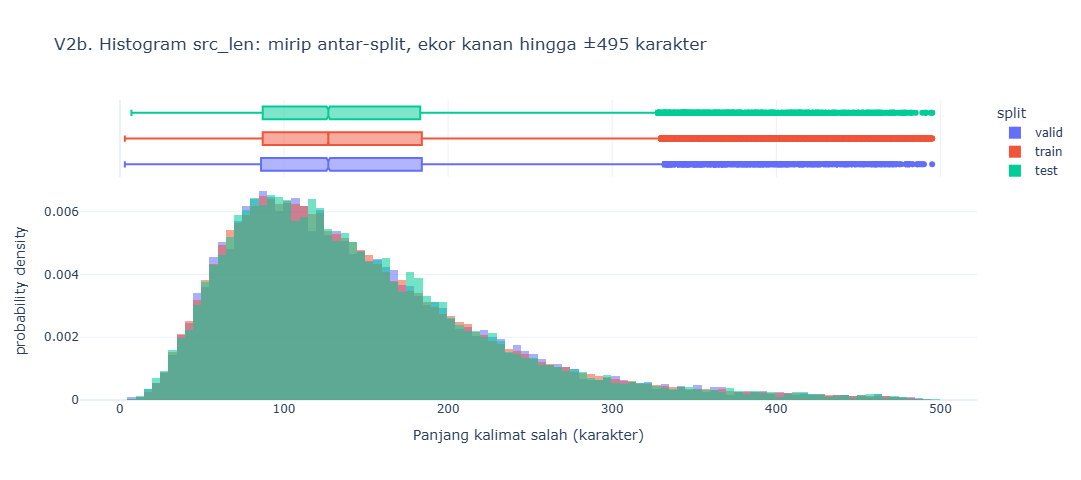

In [16]:
fig2b = px.histogram(df.sample(200_000, seed=1), x="src_len", color="split", nbins=100, barmode="overlay",
                     opacity=0.55, histnorm="probability density", marginal="box",
                     labels={"src_len": "Panjang kalimat salah (karakter)"},
                     title="V2b. Histogram src_len: mirip antar-split, ekor kanan hingga ±495 karakter")
fig2b.update_layout(height=480)
fig2b.show()

Sel 16 — Visualisasi 3: heatmap korelasi

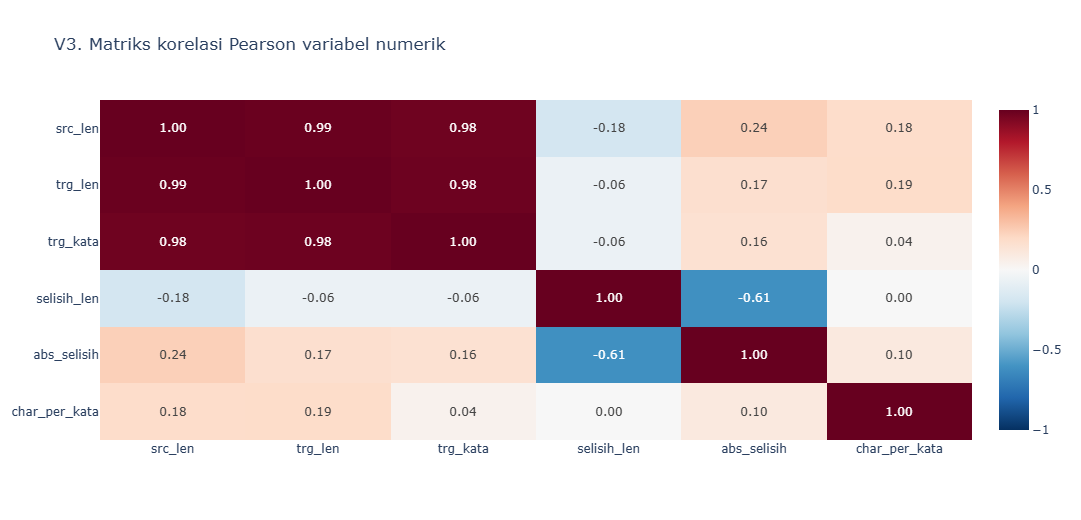

In [17]:
kol = ["src_len", "trg_len", "trg_kata", "selisih_len", "abs_selisih", "char_per_kata"]
cm = df.select(kol).corr()
fig3 = px.imshow(cm.to_numpy(), x=kol, y=kol, text_auto=".2f", zmin=-1, zmax=1,
                 color_continuous_scale="RdBu_r", aspect="auto",
                 title="V3. Matriks korelasi Pearson variabel numerik")
fig3.update_layout(height=520)
fig3.show()

Sel 17 — Visualisasi 4: treemap komposisi

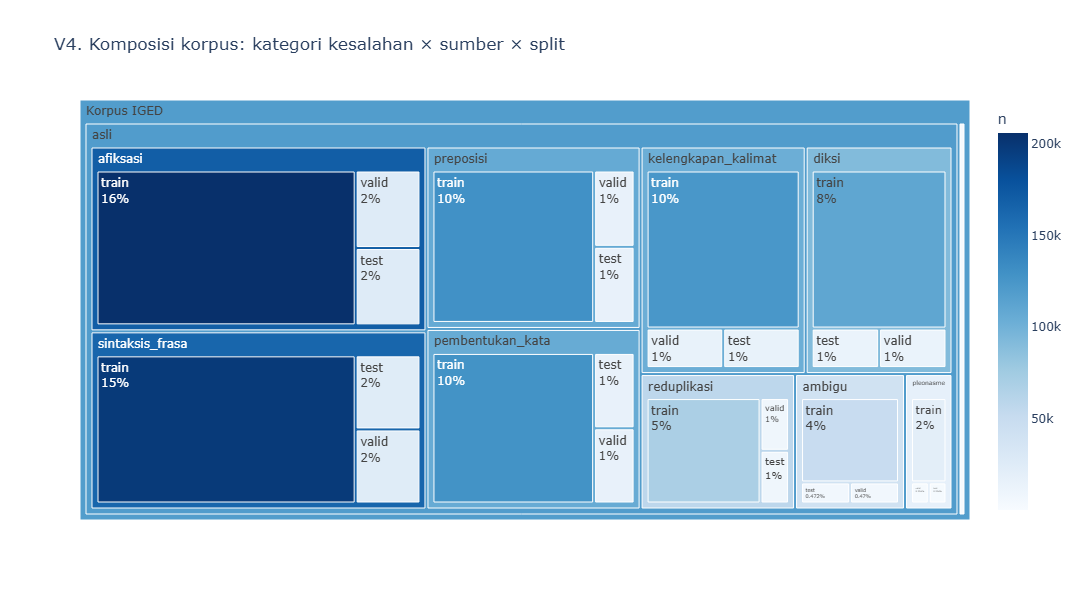

In [18]:
komp = df.group_by("sumber", "category", "split").agg(pl.len().alias("n"))
fig4 = px.treemap(komp, path=[px.Constant("Korpus IGED"), "sumber", "category", "split"], values="n",
                  color="n", color_continuous_scale="Blues",
                  title="V4. Komposisi korpus: kategori kesalahan × sumber × split")
fig4.update_traces(textinfo="label+percent root",
                   hovertemplate="%{label}<br>n=%{value:,}<br>%{percentRoot:.2%} dari total")
fig4.update_layout(height=600)
fig4.show()

Sel 18 — Visualisasi 4b: bar ketimpangan kelas

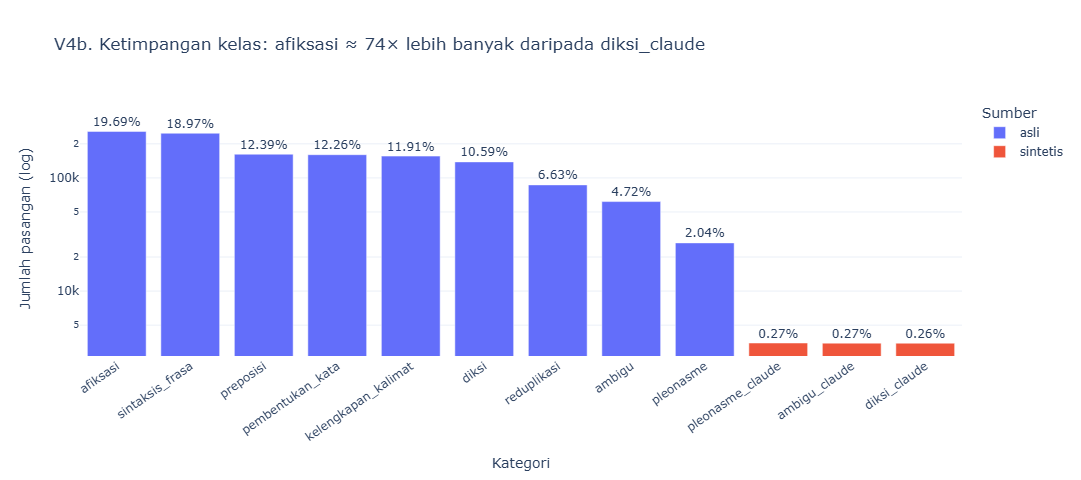

In [19]:
cnt = ringkas.sort("n", descending=True)
fig4b = px.bar(cnt, x="category", y="n", text="persen",
               color=cnt["category"].str.ends_with("_claude").map_elements(lambda b: "sintetis" if b else "asli", return_dtype=pl.String),
               log_y=True, color_discrete_map={"asli": "#636EFA", "sintetis": "#EF553B"},
               labels={"n": "Jumlah pasangan (log)", "category": "Kategori", "color": "Sumber"},
               title="V4b. Ketimpangan kelas: afiksasi ≈ 74× lebih banyak daripada diksi_claude")
fig4b.update_traces(texttemplate="%{text}%", textposition="outside")
fig4b.update_layout(height=480, xaxis_tickangle=-35)
fig4b.show()

Sel 19 — Visualisasi 5: pola berkala pada sumbu panjang kalimat

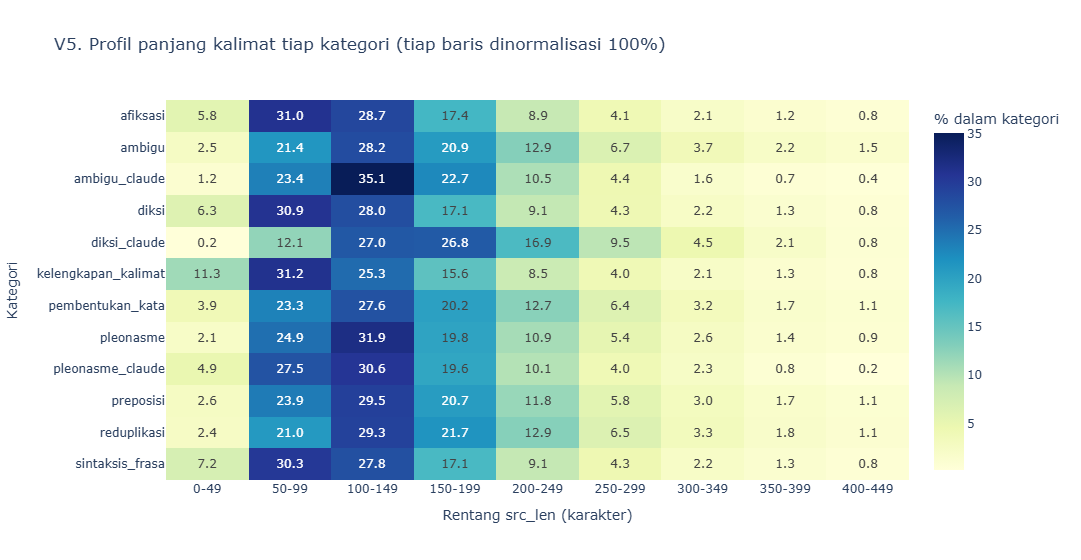

In [20]:
BIN = 50
heat = (df.with_columns(((pl.col("src_len") // BIN) * BIN).alias("bin"))
          .filter(pl.col("bin") < 450)
          .group_by("category", "bin").len()
          .with_columns((pl.col("len") / pl.col("len").sum().over("category") * 100).alias("persen_dlm_kategori"))
          .sort("bin"))
pv = heat.pivot(on="bin", index="category", values="persen_dlm_kategori").fill_null(0).sort("category")
fig5 = px.imshow(pv.drop("category").to_numpy(),
                 x=[f"{b}-{b+BIN-1}" for b in sorted(heat['bin'].unique().to_list())],
                 y=pv["category"].to_list(), text_auto=".1f", color_continuous_scale="YlGnBu", aspect="auto",
                 labels=dict(x="Rentang src_len (karakter)", y="Kategori", color="% dalam kategori"),
                 title="V5. Profil panjang kalimat tiap kategori (tiap baris dinormalisasi 100%)")
fig5.update_layout(height=560)
fig5.show()

Sel 20 — Visualisasi 5b: ECDF

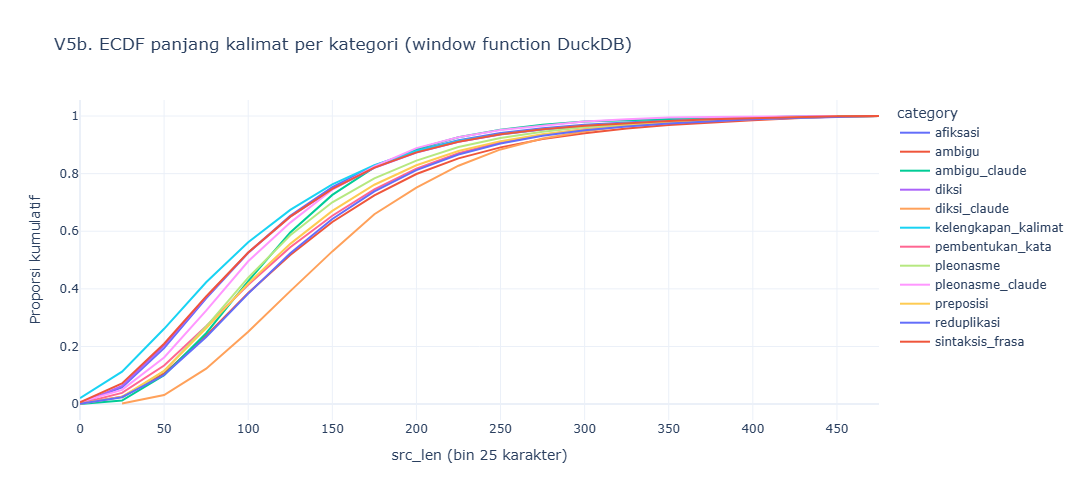

In [21]:
fig5b = px.line(ecdf.to_pandas(), x="bin_len", y="cdf", color="category",
                labels={"bin_len": "src_len (bin 25 karakter)", "cdf": "Proporsi kumulatif"},
                title="V5b. ECDF panjang kalimat per kategori (window function DuckDB)")
fig5b.update_layout(height=500, hovermode="x unified")
fig5b.show()

Sel 21 — Visualisasi 6: ruang multi-dimensi (pengganti spasial)

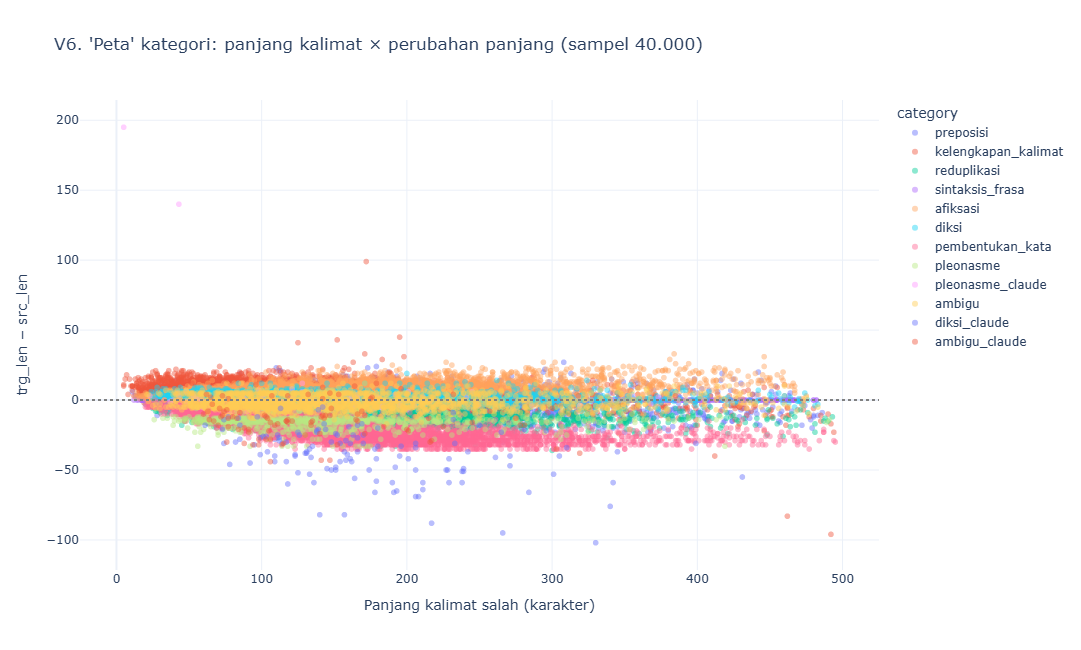

In [22]:
samp6 = df.sample(40_000, seed=11)
fig6 = px.scatter(samp6, x="src_len", y="selisih_len", color="category", opacity=0.45,
                  render_mode="webgl", hover_data=["trg_len", "trg_kata", "split"],
                  labels={"src_len": "Panjang kalimat salah (karakter)", "selisih_len": "trg_len − src_len"},
                  title="V6. 'Peta' kategori: panjang kalimat × perubahan panjang (sampel 40.000)")
fig6.add_hline(y=0, line_dash="dot", line_color="gray")
fig6.update_layout(height=650)
fig6.show()

Sel 22 — Visualisasi 7: edit ratio level kata

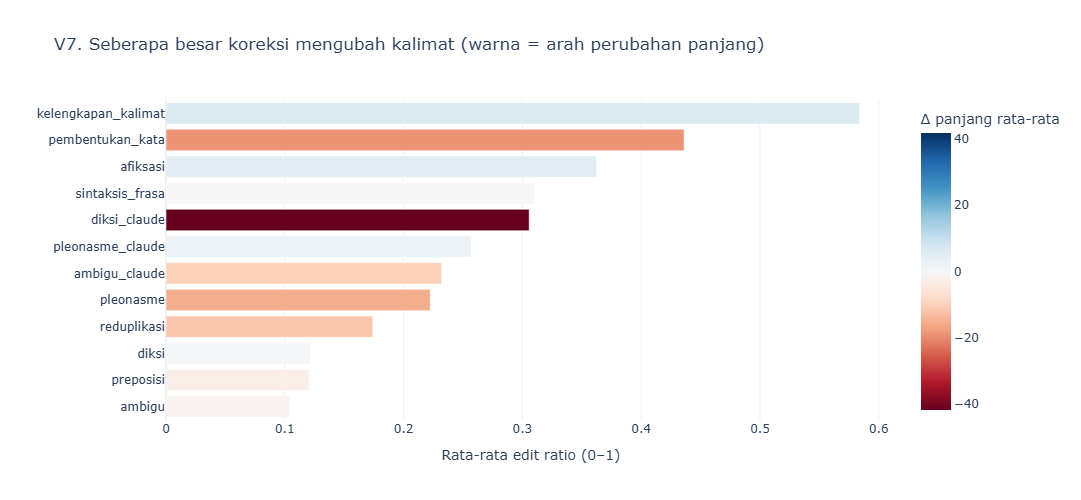

In [23]:
s = df.sample(300_000, seed=42).with_columns(
        pl.col("src").str.split(" ").alias("a"), pl.col("trg").str.split(" ").alias("b"))
s = s.with_columns(
        (1 - pl.col("a").list.set_intersection(pl.col("b")).list.len()
           / pl.col("a").list.set_union(pl.col("b")).list.len()).alias("edit_ratio"))
er = (s.group_by("category")
        .agg(pl.col("edit_ratio").mean().alias("mean"), pl.col("edit_ratio").median().alias("median"),
             pl.col("selisih_len").mean().alias("selisih_mean"))
        .sort("mean"))
fig7 = px.bar(er, x="mean", y="category", orientation="h", color="selisih_mean",
              color_continuous_scale="RdBu", color_continuous_midpoint=0,
              labels={"mean": "Rata-rata edit ratio (0–1)", "category": "", "selisih_mean": "Δ panjang rata-rata"},
              title="V7. Seberapa besar koreksi mengubah kalimat (warna = arah perubahan panjang)")
fig7.update_layout(height=500)
fig7.show()

## Rumusan Insight Analitik Utama
Semua angka di bawah diperoleh dari sel-sel di atas.

**1. Insight 1 — Tren Waktu & Musiman (urutan data): korpus stasioner, tanpa drift.**
Rata-rata `src_len` per jendela 5.000 baris selalu berkisar di sekitar 145 karakter dan rata-rata selisih panjang di sekitar −2,2 karakter, tanpa tren naik/turun yang berarti (V1). Rentang rata-rata per jendela hanya 141,6–147,9 karakter (selisih panjang −2,59 s.d. −1,81), autokorelasi lag-1 antar-jendela −0,009, dan korelasi dengan `row_id` hanya +0,10 (sangat lemah, wajar pada 261 jendela acak). Komposisi kategori per blok 200.000 baris juga praktis identik (mis. `afiksasi` ≈ 19,6–19,8% di setiap blok; perubahan antar-blok terbesar hanya ±0,18 poin persentase, hasil window function `LAG`). Split `train/valid/test` menempati blok baris yang berurutan, tetapi hasilnya stratifikasi sempurna: rata-rata `src_len` 144,77 / 144,92 / 144,93 dan proporsi tiap kategori ≈ 80/10/10. **Implikasi:** tidak ada *temporal leakage* maupun *distribution shift* antar-split, sehingga metrik valid/test dapat dipercaya mewakili train. Karena tidak ada musiman, validasi cukup dengan *random/stratified split*, tidak perlu *time-based CV*.

**2. Insight 2 — Distribusi & Anomali: miring kanan, ada pola "terlalu rapi" serta noise.**
`src_len` miring kanan (median 127, rata-rata 144,8, p95 = 304, p99 = 415, maksimum 495; 1,3% baris > 400 karakter). Anomali paling mencolok: **100% dari 248.241 baris `sintaksis_frasa` memiliki `src_len == trg_len`** (selisih = 0, std = 0), artinya kesalahannya hanya substitusi/pertukaran huruf (typo) tanpa penambahan atau penghapusan karakter. Pencilan lain ada pada `diksi_claude` (selisih rata-rata −41 ± 20 karakter, sedangkan `diksi` asli +0,5 ± 3,1), yaitu data sintetis dengan pola yang sangat berbeda dari data asli. Ada juga noise: 12.495 baris (0,96%) memiliki `src` < 30 karakter, 41% di antaranya `kelengkapan_kalimat`; sebagian berupa fragmen seperti `"8 ."` atau `"r"` yang dipasangkan dengan kalimat penuh. Terdapat pula 55 `src` yang muncul lebih dari sekali dengan koreksi berbeda (61 baris ekstra). **Implikasi:** perlu filter/penandaan baris fragmen sebelum pelatihan, dan `max_length` sekitar p99 (≈ 415 karakter) sudah cukup untuk hampir seluruh data.

**3. Insight 3 — Korelasi Kunci: panjang sumber hampir menentukan panjang target, yang informatif justru selisihnya.**
`src_len` dan `trg_len` berkorelasi sangat kuat (r ≈ 0,99), dan `src_len` dengan `trg_kata` r ≈ 0,98 (V3). Rata-rata karakter per kata ≈ 7,25, sehingga panjang karakter dan jumlah kata nyaris redundan sebagai fitur. Korelasi `selisih_len` dengan `src_len` lemah-negatif (r ≈ −0,18): kalimat yang lebih panjang cenderung *dipendekkan*, terutama karena bauran kategori (`pembentukan_kata`, `reduplikasi`, `diksi_claude` punya `src` lebih panjang dan target lebih pendek). **Implikasi:** panjang kalimat saja tidak membedakan jenis kesalahan, tetapi **tanda dan besar selisih panjang** merupakan fitur diskriminatif yang murah (V6) dan bisa dipakai sebagai *baseline* atau fitur bantu klasifikasi jenis kesalahan.

**4. Insight 4 — Perilaku Kategori: tiga kelompok koreksi dengan "sidik jari" berbeda.**
(a) *Mempertahankan panjang:* `sintaksis_frasa` (0,0), `diksi` (+0,5), `ambigu` (−1,1), `preposisi` (−2,6).
(b) *Memendekkan:* `pembentukan_kata` (−19,1), `pleonasme` (−15,4; selalu negatif, min −33 dan maks −5), `reduplikasi` (−11,5).
(c) *Memanjangkan:* `kelengkapan_kalimat` (+5,8), `afiksasi` (+4,9).

Pada edit ratio tingkat kata (V7), `kelengkapan_kalimat` adalah koreksi paling "berat" (≈ 0,58), disusul `pembentukan_kata` (≈ 0,44) dan `afiksasi` (≈ 0,36), sedangkan `ambigu` (≈ 0,10), `preposisi` dan `diksi` (≈ 0,12) hanya mengubah sedikit kata. Ketimpangan kelas juga besar (V4): `afiksasi` 19,7% dan `sintaksis_frasa` 19,0%, versus `pleonasme` 2,0% dan tiga kategori sintetis `_claude` masing-masing hanya ≈ 0,26–0,27% (total 10.411 baris ≈ 0,8%). **Implikasi:** kategori yang butuh banyak edit (`kelengkapan_kalimat`, `pembentukan_kata`) kemungkinan paling sulit bagi model; kategori minoritas rawan "tenggelam" jika hanya dilihat dari metrik agregat.

**5. Insight 5 — Rekomendasi Praktis.**
1. **Evaluasi per kategori** (macro-average, bukan hanya agregat) karena ketimpangan kelas hingga ≈ 74×; pertimbangkan *class weighting*/*oversampling* untuk `pleonasme` dan kategori `_claude`.
2. **Perlakukan data sintetis `_claude` secara terpisah** (laporkan metrik dengan dan tanpa data ini, atau audit sampel manual), karena distribusinya berbeda jauh dari data asli, misalnya `diksi_claude` memotong ≈ 41 karakter per kalimat sedangkan `diksi` asli hampir tidak mengubah panjang.
3. **Bersihkan noise tambahan:** tandai/hapus fragmen `src` < 30 karakter yang tidak masuk akal, tinjau 55 `src` duplikat dengan koreksi berbeda (potensi ambiguitas label), dan tetapkan `max_length` ≈ p99.
4. **Gunakan metrik berbasis edit** (mis. GLEU/ERRANT atau edit-distance) alih-alih akurasi kalimat utuh, karena banyak koreksi hanya mengubah < 15% kata (`ambigu`, `preposisi`, `diksi`) dan *exact match* akan menyembunyikan perbedaan kualitas.
5. **Manfaatkan sifat `sintaksis_frasa`** (panjang tetap, perubahan level karakter): model *character-level* atau aturan/kamus ejaan kemungkinan sudah cukup kompetitif untuk kategori terbesar kedua ini.
6. Karena korpus stasioner dan split sudah terstratifikasi, eksperimen dapat dibandingkan langsung antar-split tanpa penyesuaian tambahan.